In [2]:
# 1: 구글 드라이브 마운트 및 7-Zip 설치
# 분할 압축(.zip.part0)을 안정적으로 풀기 위해 p7zip-full을 설치합니다.

from google.colab import drive
drive.mount('/content/drive')

!apt-get update -qq && apt-get install -y -qq p7zip-full

Mounted at /content/drive
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [3]:
# 2: download.tar 1차 압축 해제
# 드라이브의 download.tar를 /content/tar_extracted 폴더에 풉니다. 일부 항목 경로에 특수문자(?)가 있더라도 전체 실행이 멈추지 않도록 처리합니다.

import os
import subprocess
from pathlib import Path

TAR_PATH = "/content/drive/MyDrive/AIHub_Data/download.tar"  # 실제 드라이브 경로로 수정
TAR_OUT_DIR = "/content/tar_extracted"

os.makedirs(TAR_OUT_DIR, exist_ok=True)

# 1차 tar 해제 (--warning=no-unknown-keyword 등으로 진행, 일부 깨진 엔트리는 건너뜀)
cmd = ["tar", "-xvf", TAR_PATH, "-C", TAR_OUT_DIR]
proc = subprocess.run(cmd, text=True, capture_output=True)

print("tar 종료 코드:", proc.returncode)
if proc.stderr:
    print("일부 경고/오류 요약 (상위 10줄):")
    for line in proc.stderr.strip().splitlines()[:10]:
        print("  ", line)

tar 종료 코드: 0


In [5]:
# 3: 분할 압축(.zip.part0) 2차 일괄 해제 (전체 또는 학년 필터링)
# 1차 해제 후 생성된 .zip.part0 파일들을 찾아 7-Zip으로 한 번에 풉니다.

# 전체 해제: TARGET_FILTER = ""

# 특정 학년만 해제(예: 고등 1학년): TARGET_FILTER = "08.고등학교_1학년" 또는 "고등"

import shutil

UNZIPPED_DIR = "/content/unzipped_data"
TARGET_FILTER = ""  # 예: "08.고등학교_1학년" 으로 설정하면 해당 학년만 압축 해제

os.makedirs(UNZIPPED_DIR, exist_ok=True)

part0_files = sorted(Path(TAR_OUT_DIR).rglob("*.zip.part0"))

if TARGET_FILTER:
    part0_files = [f for f in part0_files if TARGET_FILTER in str(f)]

print(f"총 {len(part0_files)}개의 .zip.part0 분할 압축 세트를 찾았습니다.")

for idx, part0 in enumerate(part0_files, 1):
    # 원본 Training / Validation 및 01.원천데이터 / 02.라벨링데이터 구조 유지
    rel_parent = part0.parent.relative_to(TAR_OUT_DIR)
    archive_folder_name = part0.name.replace(".zip.part0", "")
    dest_dir = Path(UNZIPPED_DIR) / rel_parent / archive_folder_name
    dest_dir.mkdir(parents=True, exist_ok=True)

    print(f"[{idx}/{len(part0_files)}] 압축 해제 중: {part0.name}")
    result = subprocess.run(
        ["7z", "x", str(part0), f"-o{dest_dir}", "-y"],
        text=True,
        capture_output=True
    )
    if result.returncode != 0:
        print(f"  ⚠️ 경고/오류 발생 ({part0.name}): {result.stderr.strip().splitlines()[-1] if result.stderr else ''}")

print("\n✅ 모든 압축 해제 작업이 완료되었습니다.")

총 64개의 .zip.part0 분할 압축 세트를 찾았습니다.
[1/64] 압축 해제 중: TS_01.초등학교_3학년_01.객관식.zip.part0
[2/64] 압축 해제 중: TS_01.초등학교_3학년_02.주관식.zip.part0
[3/64] 압축 해제 중: TS_02.초등학교_4학년_01.객관식.zip.part0
[4/64] 압축 해제 중: TS_02.초등학교_4학년_02.주관식.zip.part0
[5/64] 압축 해제 중: TS_03.초등학교_5학년_01.객관식.zip.part0
[6/64] 압축 해제 중: TS_03.초등학교_5학년_02.주관식.zip.part0
[7/64] 압축 해제 중: TS_04.초등학교_6학년_01.객관식.zip.part0
[8/64] 압축 해제 중: TS_04.초등학교_6학년_02.주관식.zip.part0
[9/64] 압축 해제 중: TS_05.중학교_1학년_01.객관식.zip.part0
[10/64] 압축 해제 중: TS_05.중학교_1학년_02.주관식.zip.part0
[11/64] 압축 해제 중: TS_06.중학교_2학년_01.객관식.zip.part0
[12/64] 압축 해제 중: TS_06.중학교_2학년_02.주관식.zip.part0
[13/64] 압축 해제 중: TS_07.중학교_3학년_01.객관식.zip.part0
[14/64] 압축 해제 중: TS_07.중학교_3학년_02.주관식.zip.part0
[15/64] 압축 해제 중: TS_08.고등학교_1학년_01.객관식.zip.part0
[16/64] 압축 해제 중: TS_08.고등학교_1학년_02.주관식.zip.part0
[17/64] 압축 해제 중: TL_01.초등학교_3학년_01.객관식.zip.part0
[18/64] 압축 해제 중: TL_01.초등학교_3학년_02.주관식.zip.part0
[19/64] 압축 해제 중: TL_02.초등학교_4학년_01.객관식.zip.part0
[20/64] 압축 해제 중: TL_02.초등학교_4학년_02.주관식.zip.part0


In [6]:
# 4: 해제 결과 요약 확인 (png / json 개수 점검)
# 원천데이터(.png)와 라벨링데이터(.json)가 제대로 풀렸는지 확인합니다.

png_files = list(Path(UNZIPPED_DIR).rglob("*.png"))
json_files = list(Path(UNZIPPED_DIR).rglob("*.json"))

print(f"추출된 PNG 이미지 수: {len(png_files):,}개")
print(f"추출된 JSON 라벨 수 : {len(json_files):,}개")

for p in png_files[:5]:
    print("  예시 PNG :", p)
for j in json_files[:5]:
    print("  예시 JSON:", j)

추출된 PNG 이미지 수: 18,280개
추출된 JSON 라벨 수 : 18,280개
  예시 PNG : /content/unzipped_data/30.수학_교과_문제_풀이과정_데이터/3.개방데이터/1.데이터/Training/01.원천데이터/TS_01.초등학교_3학년_02.주관식/S3_초등_3_012550.png
  예시 PNG : /content/unzipped_data/30.수학_교과_문제_풀이과정_데이터/3.개방데이터/1.데이터/Training/01.원천데이터/TS_01.초등학교_3학년_02.주관식/S3_초등_3_012011.png
  예시 PNG : /content/unzipped_data/30.수학_교과_문제_풀이과정_데이터/3.개방데이터/1.데이터/Training/01.원천데이터/TS_01.초등학교_3학년_02.주관식/S3_초등_3_011943.png
  예시 PNG : /content/unzipped_data/30.수학_교과_문제_풀이과정_데이터/3.개방데이터/1.데이터/Training/01.원천데이터/TS_01.초등학교_3학년_02.주관식/S3_초등_3_012471.png
  예시 PNG : /content/unzipped_data/30.수학_교과_문제_풀이과정_데이터/3.개방데이터/1.데이터/Training/01.원천데이터/TS_01.초등학교_3학년_02.주관식/S3_초등_3_012554.png
  예시 JSON: /content/unzipped_data/30.수학_교과_문제_풀이과정_데이터/3.개방데이터/1.데이터/Training/02.라벨링데이터/TL_07.중학교_3학년_01.객관식/S3_중등_3_013294.json
  예시 JSON: /content/unzipped_data/30.수학_교과_문제_풀이과정_데이터/3.개방데이터/1.데이터/Training/02.라벨링데이터/TL_07.중학교_3학년_01.객관식/S3_중등_3_012948.json
  예시 JSON: /content/unzipped_data/30.수학_교과_문제_풀이과정_데이터/

압축 해제 결과가 아주 깔끔합니다! PNG 이미지 18,280개와 JSON 라벨 18,280개의 개수가 정확히 1:1로 일치하고, S3_초등_3_012550.png / S3_중등_3_013294.json처럼 파일명 규칙도 일관되게 매칭되는 구조입니다.

이제 실제 학습/RAG/진단 파이프라인에서 바로 쓸 수 있는 형태로 데이터를 검증하고 정제하는 단계로 넘어가면 됩니다.

1. 현재 데이터 상태 요약
1:1 쌍 정합성 확인 완료: PNG 18,280개, JSON 18,280개로 누락이나 과잉 없이 쌍을 맞출 수 있는 상태입니다.

경로·파일명 규칙 확인:

원천 이미지: .../01.원천데이터/TS_XX.학년_YY.유형/S3_급수_학년_일련번호.png

라벨링 JSON: .../02.라벨링데이터/TL_XX.학년_YY.유형/S3_급수_학년_일련번호.json

파일명(확장자 제외 stem) 기준으로 두 폴더를 인덱싱하면 전체 18,280건을 빠르게 매칭할 수 있습니다.

2. 다음 권장 작업 (목적에 따른 선택)
① 샘플 JSON 1개 구조 확인 (가장 먼저 추천)
실제 JSON 파일 안에 어떤 키 이름으로 문제 텍스트(LaTeX), 단계별 풀이, 정답, 단원/성취기준, 난이도가 들어 있는지 먼저 확인해야 정확한 파싱 코드를 짤 수 있습니다. 아래 코드를 Colab 셀에 넣어 샘플 1개를 출력해 보세요.

In [7]:
import json
from pathlib import Path

sample_json = Path("/content/unzipped_data/30.수학_교과_문제_풀이과정_데이터/3.개방데이터/1.데이터/Training/02.라벨링데이터/TL_07.중학교_3학년_01.객관식/S3_중등_3_013294.json")

with open(sample_json, "r", encoding="utf-8") as f:
    data = json.load(f)

print(json.dumps(data, ensure_ascii=False, indent=2)[:2500])  # 앞부분 2,500자 확인

{
  "raw_data_info": {
    "raw_data_name": "31d08b44-2d40-4386-8bdb-58a387558127",
    "date": "2024-11-04",
    "publisher": "교학사",
    "publication_year": "2022-05-01",
    "school": "중학교",
    "grade": "3학년",
    "semester": "2학기",
    "subject": "수학",
    "revision_year": "2015"
  },
  "source_data_info": {
    "source_data_name": "S3_중등_3_013294",
    "2009_achievement_standard": [
      " "
    ],
    "2015_achievement_standard": [
      "[9수04-19] 원의 현에 관한 성질과 접선에 관한 성질을 이해한다."
    ],
    "2022_achievement_standard": [
      "[9수03-18] 원의 현에 관한 성질과 접선에 관한 성질을 이해하고 정당화할 수 있다."
    ],
    "level_of_difficulty": "중",
    "types_of_problems": "객관식"
  },
  "learning_data_info": [
    {
      "class_num": 1,
      "class_name": "문항(텍스트)",
      "class_info_list": [
        {
          "Type": "Bounding_Box",
          "Type_value": [
            [
              63.6,
              32.54,
              322.8,
              196.74
            ]
          ],
          "text_description"

샘플 JSON(S3_중등_3_013294.json) 구조가 아주 명확합니다!
단순한 텍스트나 정답만 있는 것이 아니라, 교육과정 성취기준(2015/2022) 메타데이터와 learning_data_info 리스트 안에 각 요소별 Bounding Box 좌표 및 설명(text_description)이 들어 있는 구조입니다.

이 구조를 바탕으로 실제 파이프라인에서 바로 쓸 수 있는 정제 방향과 변환 코드를 정리해 드립니다.

1. 샘플 JSON 스키마 핵심 포인트
raw_data_info: 출판사(교학사), 학교/학년/학기(중학교, 3학년, 2학기), 교육과정(2015 개정) 등 메타데이터가 들어 있습니다.

source_data_info: source_data_name(S3_중등_3_013294), 2015·2022 성취기준, 난이도(중), 문항 유형(객관식)이 있습니다.

learning_data_info: class_name 기준으로 항목이 나뉘어 있습니다.

문항(텍스트): LaTeX 수식이 포함된 문제 지문 (text_description)

문항(이미지): 도형/그림 바운딩 박스(Type_value)와 그림 설명(text_description)

정답(텍스트): 정답 항목 (⑤ $34^{\\circ}$)

오답(텍스트): 오답 선택지들 (JSON 뒷부분에는 풀이 관련 항목도 이어져 있을 수 있습니다.)

2. 권장 전처리 포맷 (.jsonl 정규화)
18,280건을 매번 원본 JSON의 깊은 계층 구조로 읽으면 코드가 복잡해지므로, 1문항 = 1줄(JSON 객체) 형태의 경량 .jsonl 파일로 먼저 통합해 두는 것이 가장 좋습니다.

VLM 학습/추론용 레코드 예시 필드:

id: S3_중등_3_013294

image_path: 매칭된 .png 파일 경로

meta: 학교, 학년, 학기, 출판사, 난이도, 유형, 성취기준(2015/2022)

question_text: 문제 텍스트

image_description & bboxes: 도형/텍스트 영역 정보

answer & distractors: 정답 및 오답 보기

solution (있는 경우): 풀이 과정

3. Colab용 매칭 검증 + 통합 .jsonl 생성 스크립트
아래 코드를 Colab 셀에 실행하면 /content/unzipped_data 아래의 .png 18,280개와 .json 18,280개를 stem 기준으로 1:1 매칭하고, 정제된 dataset_index.jsonl과 dataset_vlm_sft.jsonl을 생성합니다.

In [8]:
import json
from pathlib import Path

BASE_DIR = Path("/content/unzipped_data")
OUT_DIR = Path("/content/processed_math_data")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# 1. PNG 및 JSON 파일 인덱싱 (파일명 stem 기준)
png_map = {p.stem: str(p) for p in BASE_DIR.rglob("*.png")}
json_map = {j.stem: str(j) for j in BASE_DIR.rglob("*.json")}

common_keys = sorted(set(png_map.keys()) & set(json_map.keys()))
print(f"총 PNG: {len(png_map):,} | 총 JSON: {len(json_map):,} | 1:1 매칭 수: {len(common_keys):,}")

def extract_learning_fields(learning_list):
    q_texts = []
    img_descs = []
    bboxes = []
    answers = []
    wrong_choices = []
    solutions = []

    for item in learning_list or []:
        cname = item.get("class_name", "")
        for info in item.get("class_info_list", []):
            desc = (info.get("text_description") or "").strip()
            tval = info.get("Type_value")
            if tval:
                bboxes.append({"class_name": cname, "type": info.get("Type"), "value": tval})

            if "문항(텍스트)" in cname and desc:
                q_texts.append(desc)
            elif "문항(이미지)" in cname and desc:
                img_descs.append(desc)
            elif "정답" in cname and desc:
                answers.append(desc)
            elif "오답" in cname and desc:
                wrong_choices.append(desc)
            elif "풀이" in cname or "해설" in cname:
                if desc:
                    solutions.append(desc)

    return {
        "question_text": "\n".join(q_texts),
        "image_description": "\n".join(img_descs),
        "answer": " / ".join(answers),
        "wrong_choices": wrong_choices,
        "solution": "\n".join(solutions),
        "bboxes": bboxes,
    }

index_path = OUT_DIR / "math_problems_index.jsonl"
vlm_sft_path = OUT_DIR / "math_vlm_sft.jsonl"

matched_count = 0
error_count = 0

with open(index_path, "w", encoding="utf-8") as f_idx, \
     open(vlm_sft_path, "w", encoding="utf-8") as f_vlm:

    for stem in common_keys:
        try:
            with open(json_map[stem], "r", encoding="utf-8") as jf:
                raw = json.load(jf)

            raw_info = raw.get("raw_data_info", {})
            src_info = raw.get("source_data_info", {})
            parsed = extract_learning_fields(raw.get("learning_data_info", []))

            record = {
                "id": stem,
                "image_path": png_map[stem],
                "json_path": json_map[stem],
                "school": raw_info.get("school"),
                "grade": raw_info.get("grade"),
                "semester": raw_info.get("semester"),
                "subject": raw_info.get("subject"),
                "publisher": raw_info.get("publisher"),
                "curriculum_year": raw_info.get("revision_year"),
                "difficulty": src_info.get("level_of_difficulty"),
                "problem_type": src_info.get("types_of_problems"),
                "ach_2015": src_info.get("2015_achievement_standard", []),
                "ach_2022": src_info.get("2022_achievement_standard", []),
                **parsed
            }

            f_idx.write(json.dumps(record, ensure_ascii=False) + "\n")

            # VLM 대화형 SFT 포맷 생성
            target_parts = []
            if record["question_text"]:
                target_parts.append(f"[문제]\n{record['question_text']}")
            if record["solution"]:
                target_parts.append(f"[풀이]\n{record['solution']}")
            if record["answer"]:
                target_parts.append(f"[정답]\n{record['answer']}")

            vlm_sample = {
                "id": stem,
                "image": record["image_path"],
                "messages": [
                    {
                        "role": "user",
                        "content": f"<image>\n({record['school']} {record['grade']} 수학) 이미지의 수학 문제를 읽고 풀이와 정답을 제시하세요."
                    },
                    {
                        "role": "assistant",
                        "content": "\n\n".join(target_parts)
                    }
                ]
            }
            f_vlm.write(json.dumps(vlm_sample, ensure_ascii=False) + "\n")
            matched_count += 1

        except Exception as e:
            error_count += 1

print(f"완료! 정상 처리: {matched_count:,}건 | 오류: {error_count:,}건")
print("생성 파일:", index_path, "및", vlm_sft_path)

총 PNG: 18,280 | 총 JSON: 18,280 | 1:1 매칭 수: 18,280
완료! 정상 처리: 18,280건 | 오류: 0건
생성 파일: /content/processed_math_data/math_problems_index.jsonl 및 /content/processed_math_data/math_vlm_sft.jsonl


18,280건 전체가 1:1로 매칭되고 오류 0건으로 정상 처리되어 math_problems_index.jsonl과 math_vlm_sft.jsonl이 깔끔하게 생성되었습니다. 이제 원천 이미지와 라벨링 JSON을 일일이 탐색하지 않고도, 정제된 .jsonl 파일 두 개를 기반으로 바로 실험·학습·검색 파이프라인을 돌릴 수 있는 준비가 끝났습니다.

1. 지금 바로 해두면 좋은 2가지 작업
① 구글 드라이브에 결과물 백업 (세션 휘발 방지)
Colab /content/processed_math_data 폴더는 런타임이 끊기거나 초기화되면 사라집니다. 나중에 다시 압축을 풀고 전처리하는 수고를 덜려면 생성된 .jsonl 파일들을 구글 드라이브에 복사해 두는 것이 안전합니다.

In [9]:
import shutil
from pathlib import Path

src_dir = Path("/content/processed_math_data")
dst_dir = Path("/content/drive/MyDrive/AIHub_Data/processed_math_data")
dst_dir.mkdir(parents=True, exist_ok=True)

for fname in ["math_problems_index.jsonl", "math_vlm_sft.jsonl"]:
    shutil.copy2(src_dir / fname, dst_dir / fname)
    print("백업 완료:", dst_dir / fname)

백업 완료: /content/drive/MyDrive/AIHub_Data/processed_math_data/math_problems_index.jsonl
백업 완료: /content/drive/MyDrive/AIHub_Data/processed_math_data/math_vlm_sft.jsonl


② 데이터 분포 및 비어 있는 필드 점검
18,280건 중 학교급/학년/난이도 분포와 solution(풀이)이나 question_text가 비어 있는 샘플이 얼마나 있는지 한 번 확인해 두면, 이후 학습용/평가용 데이터셋을 나눌 때 실수를 줄일 수 있습니다.

In [10]:
import json
from collections import Counter

index_path = "/content/processed_math_data/math_problems_index.jsonl"

grade_counts = Counter()
empty_sol = 0
empty_q = 0
total = 0

with open(index_path, "r", encoding="utf-8") as f:
    for line in f:
        row = json.loads(line)
        total += 1
        grade_counts[f"{row.get('school')} {row.get('grade')} ({row.get('problem_type')})"] += 1
        if not (row.get("solution") or "").strip():
            empty_sol += 1
        if not (row.get("question_text") or "").strip():
            empty_q += 1

print(f"총 문항 수: {total:,}")
print(f"문제 텍스트 누락: {empty_q:,} | 풀이 필드 비어있음: {empty_sol:,}\n")
print("[학년/유형별 분포]")
for k, v in sorted(grade_counts.items()):
    print(f"  {k}: {v:,}건")

총 문항 수: 18,280
문제 텍스트 누락: 60 | 풀이 필드 비어있음: 101

[학년/유형별 분포]
  고등학교 1학년 (객관식): 537건
  고등학교 1학년 (주관식): 534건
  중학교 1학년 (객관식): 2,014건
  중학교 1학년 (주관식): 1,085건
  중학교 2학년 (객관식): 2,296건
  중학교 2학년 (주관식): 915건
  중학교 3학년 (객관식): 2,286건
  중학교 3학년 (주관식): 561건
  초등학교 3학년 (객관식): 1,359건
  초등학교 3학년 (주관식): 494건
  초등학교 4학년 (객관식): 1,374건
  초등학교 4학년 (주관식): 499건
  초등학교 5학년 (객관식): 1,266건
  초등학교 5학년 (주관식): 794건
  초등학교 6학년 (객관식): 1,352건
  초등학교 6학년 (주관식): 914건


데이터 품질이 아주 훌륭합니다! 총 18,280건 중 문제 텍스트 누락이 60건(약 0.33%), 풀이 필드 누락이 101건(약 0.55%)에 불과하니, 18,100건 이상이 문제와 풀이를 모두 갖춘 고품질 데이터라는 뜻입니다.

1. 주요 분포 요약
전체 규모: 18,280건

학교급별 대략적 비중:

중학교 (1~3학년): 총 10,077건 (중1: 3,099 / 중2: 3,211 / 중3: 2,847) — 가장 방대한 핵심 구간

초등학교 (3~6학년): 총 7,131건 (초3: 1,853 / 초4: 1,873 / 초5: 2,060 / 초6: 2,266)

고등학교 (1학년): 총 1,071건 (객관식: 537 / 주관식: 534)

유형별 특징: 중·고등 및 초등 모두 객관식 비중이 높고, 주관식 문항도 1,071건(고1 534건 등) 확보되어 있어 풀이 과정 서술형 학습이나 진단용으로 활용하기 좋습니다.

2. 파이프라인 투입 전 권장 정제(필터링) 기준
결측치 제외: question_text와 solution이 모두 존재하는 문항(약 18,120건 수준)만 골라 학습/RAG 기본 코퍼스로 삼는 것이 안전합니다.

목적별 서브셋 분리:

VLM 파인튜닝 / 추론 검증용: 이미지(.png) + 문제(LaTeX) + 단계별 풀이 + 정답이 온전히 있는 문항을 선별해 train / val로 나눕니다. 특히 주관식 문항이나 도형/그래프 설명(image_description)이 포함된 문항은 시각 추론·풀이 생성 테스트에 유용합니다.

RAG / 성취기준 검색용: ach_2015, ach_2022, school, grade, semester, question_text, solution, answer를 한 덩어리(문서)로 구성하면, 특정 단원이나 성취기준 기반의 유사 문항·개념·풀이 검색에 바로 쓸 수 있습니다.

3. 고품질 서브셋 추출 + train/val 분할 코드 예시
결측치를 제거하고, 원하는 학교급/학년(예: ["중학교", "고등학교"] 또는 전체 None) 기준으로 정제된 .jsonl을 만드는 코드입니다.

In [11]:
import json
import random
from pathlib import Path

SRC_JSONL = Path("/content/processed_math_data/math_problems_index.jsonl")
OUT_DIR = Path("/content/processed_math_data/clean_splits")
OUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET_SCHOOLS = None  # 예: ["중학교", "고등학교"] 또는 전체 사용 시 None
VAL_RATIO = 0.1
SEED = 42

clean_rows = []
with open(SRC_JSONL, "r", encoding="utf-8") as f:
    for line in f:
        row = json.loads(line)
        q = (row.get("question_text") or "").strip()
        s = (row.get("solution") or "").strip()
        if not q or not s:
            continue
        if TARGET_SCHOOLS and row.get("school") not in TARGET_SCHOOLS:
            continue
        clean_rows.append(row)

random.Random(SEED).shuffle(clean_rows)
val_size = int(len(clean_rows) * VAL_RATIO)
val_rows = clean_rows[:val_size]
train_rows = clean_rows[val_size:]

def save_jsonl(rows, path):
    with open(path, "w", encoding="utf-8") as out:
        for r in rows:
            out.write(json.dumps(r, ensure_ascii=False) + "\n")

save_jsonl(train_rows, OUT_DIR / "train.jsonl")
save_jsonl(val_rows, OUT_DIR / "val.jsonl")

print(f"정제 완료 문항 수: {len(clean_rows):,}건")
print(f"  - Train: {len(train_rows):,}건 -> {OUT_DIR / 'train.jsonl'}")
print(f"  - Val  : {len(val_rows):,}건 -> {OUT_DIR / 'val.jsonl'}")

정제 완료 문항 수: 18,121건
  - Train: 16,309건 -> /content/processed_math_data/clean_splits/train.jsonl
  - Val  : 1,812건 -> /content/processed_math_data/clean_splits/val.jsonl



## 이 정제된 데이터를 VLM 학습/추론 쪽으로 연결할지, 아니면 성취기준·단원 기반 RAG 검색 및 오답 진단 쪽으로 먼저 구현
두 가지 접근 방식 모두 학생의 학습 상태나 취약 단원에 맞춰 문제와 피드백을 제공한다는 공통점이 있지만, 어떻게 문제를 만들어내고(생성형 VLM vs 검색·추적형 RAG) 학생의 오답을 다루는지에서 실제 학생 경험과 가능 범위가 분명하게 달라집니다.

1. VLM 학습/추론 쪽: "부족한 단원에 대한 문제 생성이 가능하니?"
가능 여부와 현실적인 장점·한계
가능합니다. math_vlm_sft.jsonl에 담긴 문제 이미지(.png), 문제 텍스트(LaTeX), 풀이, 정답을 바탕으로 VLM을 학습시키면, 특정 단원·성취기준이나 문제 스타일(예: 도형/그래프 포함 문항, 서술형 풀이)을 참고해 유사 문항과 단계별 풀이를 생성할 수 있습니다.

다만 순수 VLM 생성만 쓰면 주의해야 할 점이 있습니다.

수학 문제는 숫자 하나나 조건 하나만 바뀌어도 정답이나 계산 과정이 어긋날 수 있는(연산/논리 환각) 위험이 있습니다.

따라서 실제 수업이나 학생 연습용으로 쓸 때는 생성된 문제·풀이·정답을 검증하는 단계(예: 수식/풀이 재검증이나 기존 검증된 기출·문항 은행과 결합)를 두는 것이 안전합니다.

학생이 할 수 있는 구체적 행위 (VLM 중심)
약점 단원 맞춤형 연습문제 받기: 학생이 "이차함수 꼭짓점이나 원의 접선 성질이 약해요"라고 선택하거나 시스템이 취약 단원을 잡으면, 해당 단원 성향에 맞춘 새로운 연습문제(텍스트/수식/도형 묘사 및 풀이)를 받아 풀어볼 수 있습니다.

직접 푼 손글씨·풀이 사진 올리고 피드백 받기: 학생이 노트에 푼 풀이 과정을 사진으로 찍어 올리면, VLM이 식 전개나 계산 흐름을 읽고 어느 줄에서 논리가 끊겼는지 설명해 줍니다.

비슷한 유형 반복 훈련: 틀린 문제와 유사한 구조의 변형 문제를 연속으로 받아 개념을 체화할 수 있습니다.

2. 성취기준·단원 기반 RAG + 오답 원인 역추적 쪽: "오답일 경우 prerequisite_units에 기록된 이전 단계 단원 문제로 넘어갈 수 있니?"
가능 여부와 핵심 구조
네, 아주 잘 어울리는 구조입니다. 현재 정제하신 데이터에는 2015_achievement_standard, 2022_achievement_standard, school, grade, semester, question_text, solution, answer가 들어 있으므로, 여기에 단원/성취기준별 선수학습 맵(prerequisite_units 등)을 연결하면 단순 문제 풀이를 넘어 '어디서부터 구멍이 났는지' 역추적하는 진단형 학습이 가능합니다.

작동 흐름은 다음과 같습니다.

학생이 현재 단원(예: 중3 원의 성질) 문제를 풀고 오답을 냅니다.

해당 문항의 성취기준·단원·풀이 단계와 학생의 답/풀이를 비교해 어떤 개념/계산 단계에서 막혔는지 1차 진단합니다.

해당 단원에 연결된 prerequisite_units(선수 단원/성취기준)로 내려가 기초 확인 문항(RAG 검색으로 가져온 검증된 문제)을 제시합니다.

선수 단원 문제를 맞히면 원래 단원으로 복귀하고, 선수 단원 문제도 틀리면 더 이전 단계의 선수 단원으로 한 단계 더 내려가는 역추적(재귀적/단계적 진단)을 수행합니다.

학생이 할 수 있는 구체적 행위 (RAG + 선수학습 역추적 중심)
틀린 문제의 '진짜 원인' 단계 확인하기: 단순히 "틀렸습니다"가 아니라, "이 문항을 풀려면 앞 단원의 ○○ 성질을 먼저 적용해야 하는데, 그 단계에서 막혔어요" 같은 원인 기반 피드백을 볼 수 있습니다.

구멍 난 선수 단원 문제로 자동 이동해 메우기: 현재 문제를 틀렸을 때 prerequisite_units에 연결된 이전 학년·이전 단원의 기초 문제를 바로 풀면서, 지금 단원을 못 푸는 이유가 '현재 개념 부족'인지 '기초 연산/개념 누락'인지 스스로 확인할 수 있습니다.

성취기준 단위로 학습 이력 쌓기: 어떤 성취기준에서 자주 막히고 어떤 선수 단원을 보완했는지가 기록되므로, 최소학업성취수준 미도달 학생의 보충 지도나 개별 피드백에 바로 쓸 수 있는 학습 경로가 만들어집니다.

3. 두 방식을 함께 묶을 때 가장 강력한 시나리오
실제 교육 현장에서는 둘 중 하나만 고르기보다 역할을 나누어 결합할 때 완성도가 가장 높습니다.

진단과 문제 제공(정확성 담당): 성취기준·단원 메타데이터와 prerequisite_units를 바탕으로 검증된 문항을 검색(RAG)하고, 오답 시 선수 단원으로 역추적해 정확한 기초 문항을 먼저 제공합니다.

맞춤형 설명·변형·풀이 검토(유연성 담당): 학생의 풀이 사진이나 막히는 지점을 VLM이 읽고 친절한 단계별 힌트를 주거나, 기초를 통과한 뒤 추가 연습이 필요할 때 유사 문항을 생성해 보조합니다.

## 지금 구상하시는 시스템에서는 학생이 먼저 '현재 단원 문제 풀이 → 오답 시 선수 단원 역추적' 흐름을 핵심 뼈대로 잡으시는 걸까요, 아니면 '부족한 단원 문제 생성 및 풀이 피드백' 중심으로 먼저 프로토타입을 만들어 보실까요?

'현재 단원 문제 풀이 → 오답 시 선수 단원 역추적'을 핵심 뼈대로 잡는 것은 아주 탄탄한 설계입니다. 특히 이미 확보하신 18,280건의 문항 인덱스(math_problems_index.jsonl)에 담긴 성취기준(ach_2015, ach_2022), 학년/학기, 문제, 풀이, 정답 데이터를 그대로 검색·연결 자산으로 쓸 수 있어 프로토타입부터 실제 운영까지 일관되게 끌고 갈 수 있습니다.

핵심 뼈대를 잡기 위해 전체 상태 머신 흐름, 데이터 모델(prerequisite_units), 그리고 당장 테스트해 볼 수 있는 최소 골격을 정리해 드립니다.

1. 핵심 상태 흐름 (State Machine 뼈대)
학생이 문제를 풀 때 시스템은 아래 5가지 상태를 순환하며 움직입니다.

CURRENT_UNIT_SOLVE (현재 단원 문제 풀이)

학생에게 현재 학습 단원(또는 성취기준)의 문항을 제시하고 답안(또는 풀이 과정)을 받습니다.

EVALUATE_ANSWER (정오답 및 막힌 지점 판별)

정답인 경우: 해당 단원·성취기준의 숙달도(Mastery)를 올리고, 다음 난이도나 다음 문항으로 진행합니다.

오답인 경우: 오답 횟수/유형을 기록하고 PREREQ_TRACE (선수 단원 역추적) 단계로 진입합니다.

PREREQ_TRACE (선수 단원 역추적 및 진단 문항 검색)

현재 단원/성취기준에 연결된 prerequisite_units 목록에서 아직 확인되지 않은 가장 가까운 선수 단원(또는 성취기준)을 선택합니다.

math_problems_index.jsonl에서 해당 선수 단원/성취기준에 맞는 진단용 기초 문항(RAG 후보)을 가져와 학생에게 출제합니다.

REMEDIATE_CHECK (선수 단원 확인 풀이)

선수 단원 문항을 맞힌 경우: *"이 기초 개념은 잡혀 있군요!"*라고 안내한 뒤, 다시 CURRENT_UNIT_SOLVE로 복귀해 현재 단원 문항을 재도전하게 합니다.

선수 단원 문항도 틀린 경우: 역추적 깊이(예: 최대 2~3단계)가 남았다면 그보다 더 이전의 prerequisite_units로 한 단계 더 내려가 기초 구멍을 찾습니다.

RECOVERY_AND_ADVANCE (보완 완료 및 본 단원 재진입)

내려갔던 선수 단원을 통과하면 다시 상위 단원으로 올라오며, 최종적으로 현재 단원 문항을 해결하면 학습 경로 기록을 남기고 다음 문항으로 넘어갑니다.

2. 선수 단원 맵(prerequisite_units.json) 설계 뼈대
현재 math_problems_index.jsonl에는 ach_2015와 ach_2022 성취기준 문자열이 들어 있으므로, 성취기준 코드(예: [9수03-18])나 단원 키를 기준으로 선수 학습 관계를 별도 JSON으로 매핑해 두면 코드가 훨씬 깔끔해집니다.

In [ ]:
{
  "[9수03-18]": {
    "unit_name": "원의 현과 접선의 성질",
    "school": "중학교",
    "grade": "3학년",
    "prerequisite_units": [
      {
        "unit_id": "[9수03-17]",
        "unit_name": "원의 성질(현의 수직이등분선 등)",
        "check_hint": "원의 중심에서 현에 내린 수선이 현을 이등분하는 성질을 확인합니다."
      },
      {
        "unit_id": "[8수03-08]",
        "unit_name": "삼각형의 성질(이등변삼각형·합동)",
        "check_hint": "반지름으로 만들어진 이등변삼각형의 밑각 성질을 확인합니다."
      }
    ]
  }
}

실무 팁: 처음부터 18,280건 전체의 성취기준 그래프를 한 번에 다 그리려 하기보다, 가장 먼저 시연·검증할 특정 단원(예: 중3 원/도형 또는 고등 1학년 단원) 몇 개만 prerequisite_units.json에 정의해 두고 엔드투엔드(E2E) 흐름을 먼저 돌리는 것이 훨씬 빠릅니다.

3. 프로토타입용 최소 로직 예시 (Python)
math_problems_index.jsonl에서 성취기준/학년으로 문제를 뽑아오고, 오답 시 prerequisite_units 스택을 쌓으며 역추적하는 핵심 뼈대 코드입니다.

In [12]:
import json
from collections import defaultdict
from pathlib import Path

INDEX_PATH = Path("/content/processed_math_data/math_problems_index.jsonl")

# 1. 성취기준별 문항 풀 구성 (RAG 검색의 기본 풀)
problems_by_ach = defaultdict(list)
with open(INDEX_PATH, "r", encoding="utf-8") as f:
    for line in f:
        row = json.loads(line)
        for ach in row.get("ach_2022") or []:
            ach_code = ach.split("]")[0] + "]" if "]" in ach else ach.strip()
            if ach_code:
                problems_by_ach[ach_code].append(row)

# 2. 샘플 선수학습 맵 (필요 단원부터 확장)
PREREQ_MAP = {
    "[9수03-18]": ["[9수03-17]", "[8수03-08]"],
    "[9수03-17]": ["[8수03-08]"],
    "[8수03-08]": [],
}

class PrereqTraceSession:
    def __init__(self, target_ach: str, max_depth: int = 2):
        self.target_ach = target_ach
        self.current_ach = target_ach
        self.max_depth = max_depth
        self.trace_stack = []   # 역추적 중인 선수 단원 스택
        self.visited_ach = {target_ach}
        self.history = []

    def get_next_problem(self):
        candidates = problems_by_ach.get(self.current_ach, [])
        return candidates[0] if candidates else None

    def submit_answer(self, is_correct: bool):
        depth = len(self.trace_stack)
        self.history.append({
            "ach": self.current_ach,
            "depth": depth,
            "is_correct": is_correct
        })

        if is_correct:
            # 선수 단원 역추적 중이었다면 한 단계 상위(또는 본 단원)로 복귀
            if self.trace_stack:
                self.current_ach = self.trace_stack.pop()
                return f"선수 단원 통과! 상위 단계({self.current_ach}) 문제로 돌아갑니다."
            return f"현재 단원({self.current_ach}) 정답! 다음 문항으로 진행합니다."

        # 오답인 경우: 최대 역추적 깊이 확인 후 선수 단원으로 이동
        if depth < self.max_depth:
            prereqs = PREREQ_MAP.get(self.current_ach, [])
            next_prereq = next((p for p in prereqs if p not in self.visited_ach), None)
            if next_prereq:
                self.trace_stack.append(self.current_ach)
                self.visited_ach.add(next_prereq)
                self.current_ach = next_prereq
                return f"오답 감지 → 선수 단원({self.current_ach}) 기초 문항으로 역추적합니다. (깊이 {len(self.trace_stack)})"

        return f"오답 감지 → 역추적 한계 도달. 현재 단원({self.current_ach}) 풀이 해설과 힌트를 제공합니다."

# 동작 시뮬레이션 예시
session = PrereqTraceSession("[9수03-18]", max_depth=2)
print("시작 문항:", session.get_next_problem()["id"], "| 단원:", session.current_ach)
print(session.submit_answer(False))  # 1차 오답 -> [9수03-17]
print(session.submit_answer(False))  # 2차 오답 -> [8수03-08]
print(session.submit_answer(True))   # 기초 정답 -> [9수03-17] 복귀
print(session.submit_answer(True))   # 복귀 정답 -> [9수03-18] 복귀

시작 문항: S3_중등_3_003226 | 단원: [9수03-18]
오답 감지 → 선수 단원([9수03-17]) 기초 문항으로 역추적합니다. (깊이 1)
오답 감지 → 선수 단원([8수03-08]) 기초 문항으로 역추적합니다. (깊이 2)
선수 단원 통과! 상위 단계([9수03-17]) 문제로 돌아갑니다.
선수 단원 통과! 상위 단계([9수03-18]) 문제로 돌아갑니다.


4. 다음 단계 결정 포인트
이 뼈대 위에서 다음으로 어떤 부분을 먼저 구체화할지 정하시면 바로 이어갈 수 있습니다.

ach_2022 / ach_2015 실제 값 분포 확인: 현재 math_problems_index.jsonl에 어떤 성취기준 코드와 단원명이 얼마나 들어 있는지 먼저 뽑아보기

오답 판별 및 피드백 방식 정하기: 객관식/단답형 자동 채점 외에, 학생 풀이 사진(VLM)이나 서술형 답안을 보고 "어느 단계에서 틀렸고 어떤 선수 개념이 부족한지" 판별하는 로직을 붙일지 정하기

UI/웹 프로토타입 연결: 학생이 문제를 풀고 오답 시 선수 단원 문항으로 넘어가는 화면을 Gradio나 웹 앱 형태로 띄워보기

## 우선 어떤 학년·단원(예: 중3, 고1, 또는 특정 성취기준)을 첫 번째 테스트 단원으로 잡을지와 위 1·2·3번 중 먼저 다듬고 싶은 부분을 알려주세요!

시뮬레이션 로그를 보니 선수 단원 역추적 → 기초 보완 후 상위 단계로 순차 복귀하는 핵심 뼈대가 아주 깔끔하게 작동했습니다!

1. 방금 실행된 역추적 흐름 해석
본 단원 진입: 중3 [9수03-18](S3_중등_3_003226) 문항 풀이 시작

1차 오답 → 깊이 1 하강: [9수03-18] 오답 감지 후 선수 단원 [9수03-17] 기초 문항으로 이동

2차 오답 → 깊이 2 하강: [9수03-17]에서도 오답이 나오자, 한 단계 더 기초인 [8수03-08] 문항으로 역추적

기초 통과 및 상향 복귀: [8수03-08] 문항 정답 확인 후 [9수03-17]로 복귀 → 해당 문항 통과 뒤 다시 원래 목표인 [9수03-18]로 복귀

2. 다음 단계에서 바로 붙일 수 있는 3가지 고도화 포인트
실제 데이터셋의 ach_2022 / ach_2015 코드 전수 점검

math_problems_index.jsonl에 실제로 들어 있는 성취기준 코드와 문항 수를 뽑아보면, PREREQ_MAP에 어떤 단원들을 연결해야 실제 18,280건 문항 풀에서 후보 문항을 안정적으로 가져올 수 있는지 한눈에 보입니다.

단순 candidates[0] 대신 문제 선택·오답 판별 고도화

같은 문항만 계속 나오지 않도록 미풀이 문항 우선 선택 / 난이도(하→중) 조절을 넣고, 객관식 정답 비교뿐만 아니라 학생 답안·풀이 사진(VLM)을 붙일 수 있게 판별 인터페이스를 분리해 두면 확장하기 편합니다.

학습 경로(Trace) 로그 저장

어느 단원에서 내려갔다가 어디서 막혔는지(예: [9수03-18] → [9수03-17] → [8수03-08]에서 2단계 하강 후 복귀)를 JSON 로그로 남겨 두면, 학생별 취약 성취기준 요약이나 피드백 생성에 바로 쓸 수 있습니다.

## 현재 math_problems_index.jsonl에 들어 있는 성취기준별 문항 수 상위 목록을 뽑는 코드부터 돌려보실까요, 아니면 학생 답안 입력/채점과 복귀 후 재도전 문항 출제까지 이어지는 테스트 루프를 먼저 만들어 볼까요?

학생이 실제로 답안을 입력하고, 자동 채점(객관식 기호/값 정규화 및 주관식/텍스트 유연 비교)을 거친 뒤, 오답 시 선수 단원으로 내려가 기초 문항을 풀고, 통과 후 원래 단원으로 복귀해 '다른 새 문항'을 재도전 출제하는 테스트 루프를 바로 돌려볼 수 있게 구성했습니다.

1. 테스트 루프에서 신경 쓴 핵심 디테일
중복 출제 방지(used_ids): 이전 시뮬레이션처럼 같은 문항(S3_중등_3_003226)만 반복해서 나오지 않도록, 한 번 출제한 문항 ID는 기록해 두고 아직 안 푼 문항부터 우선 출제합니다.

복귀 시 재도전 흐름 명확화: [9수03-17] → [8수03-08]로 내려가 기초 문항을 맞히면 [9수03-17]의 새 재도전 문항이 출제되고, 이를 맞히면 최종적으로 원래 단원([9수03-18])의 새 재도전 문항이 이어집니다.

채점기(Grader) 유연성: AI Hub 정답에 ⑤ $34^{\circ}$처럼 원문자·공백·LaTeX 기호($, \circ, ^{\circ})가 섞여 있을 수 있으므로, 기호/공백을 정규화해서 비교하도록 만들었습니다.

2. Colab에서 바로 실행할 수 있는 테스트 루프 코드
아래 코드를 Colab 셀에 넣고 실행해 보세요. 대화형 입력 모드(INTERACTIVE = True)로 직접 답을 입력해 볼 수도 있고, 자동 시나리오 테스트(INTERACTIVE = False)로 전체 루프를 한 번에 검증할 수도 있습니다.

In [13]:
import json
import re
from collections import defaultdict
from pathlib import Path

INDEX_PATH = Path("/content/processed_math_data/math_problems_index.jsonl")

# 1. 성취기준별 문항 풀 로드
problems_by_ach = defaultdict(list)
with open(INDEX_PATH, "r", encoding="utf-8") as f:
    for line in f:
        row = json.loads(line)
        for ach in row.get("ach_2022") or []:
            code = ach.split("]")[0] + "]" if "]" in ach else ach.strip()
            if code:
                problems_by_ach[code].append(row)

# 2. 선수학습 맵 (실제 데이터셋에 문항이 존재하는 코드 위주로 구성)
PREREQ_MAP = {
    "[9수03-18]": ["[9수03-17]", "[8수03-08]"],
    "[9수03-17]": ["[8수03-08]"],
    "[8수03-08]": [],
}

CIRCLE_NUMS = {"①": "1", "②": "2", "③": "3", "④": "4", "⑤": "5"}

def normalize_answer(text: str) -> str:
    """수식 기호, 원문자, 공백을 정리해 답안 비교 정확도를 높입니다."""
    if not text:
        return ""
    s = text.strip()
    for k, v in CIRCLE_NUMS.items():
        s = s.replace(k, v)
    # LaTeX 장식 기호 제거
    s = re.sub(r"\$+|\\mathrm\{([^}]*)\}|\\text\{([^}]*)\}|\\circ|\^?\{\\?circ\}|\s+", "", s)
    return s.lower()

def check_answer(user_ans: str, gold_ans: str) -> bool:
    """정답 문자열과 사용자 답안을 비교합니다."""
    u = normalize_answer(user_ans)
    g = normalize_answer(gold_ans)
    if not u or not g:
        return False
    if u == g:
        return True
    # 정답이 '534'처럼 선택지 번호+값으로 붙어 있는 경우 번호 또는 값 단독 일치 허용
    for k, v in CIRCLE_NUMS.items():
        if user_ans.strip() in (k, v) and v in g:
            return True
    return u in g and len(u) >= 1

class MathRemediationLoop:
    def __init__(self, target_ach: str, max_depth: int = 2):
        self.target_ach = target_ach
        self.current_ach = target_ach
        self.max_depth = max_depth
        self.trace_stack = []      # 내려온 상위 단원 스택
        self.visited_ach = {target_ach}
        self.used_problem_ids = set()
        self.current_problem = None
        self.logs = []

    def pick_problem(self, ach: str):
        pool = problems_by_ach.get(ach, [])
        # 아직 안 푼 문항 우선 선택
        unused = [p for p in pool if p["id"] not in self.used_problem_ids]
        chosen = unused[0] if unused else (pool[0] if pool else None)
        if chosen:
            self.used_problem_ids.add(chosen["id"])
        return chosen

    def start_or_get_problem(self, force_new: bool = False):
        if self.current_problem is None or force_new:
            self.current_problem = self.pick_problem(self.current_ach)
        return self.current_problem

    def step(self, user_answer: str):
        prob = self.start_or_get_problem(force_new=False)
        if not prob:
            return {"status": "NO_PROBLEM", "message": f"{self.current_ach} 문항 풀이 비어 있습니다."}

        is_correct = check_answer(user_answer, prob.get("answer", ""))
        depth = len(self.trace_stack)

        event = {
            "ach": self.current_ach,
            "problem_id": prob["id"],
            "depth": depth,
            "user_answer": user_answer,
            "gold_answer": prob.get("answer", ""),
            "is_correct": is_correct,
        }
        self.logs.append(event)

        if is_correct:
            if self.trace_stack:
                returned_ach = self.trace_stack.pop()
                self.current_ach = returned_ach
                next_prob = self.start_or_get_problem(force_new=True)
                return {
                    "status": "RECOVERED_RETRY",
                    "message": f"정답입니다! 선수 단원 학습을 마치고 상위 단계 [{self.current_ach}]로 복귀해 새 문항을 출제합니다.",
                    "next_problem": next_prob,
                }
            else:
                next_prob = self.start_or_get_problem(force_new=True)
                return {
                    "status": "CORRECT_NEXT",
                    "message": f"정답입니다! [{self.current_ach}] 단원의 다음 문항을 출제합니다.",
                    "next_problem": next_prob,
                }

        # 오답 처리 -> 선수 단원 역추적
        if depth < self.max_depth:
            prereqs = PREREQ_MAP.get(self.current_ach, [])
            next_prereq = next((p for p in prereqs if p not in self.visited_ach), None)
            if next_prereq:
                self.trace_stack.append(self.current_ach)
                self.visited_ach.add(next_prereq)
                self.current_ach = next_prereq
                next_prob = self.start_or_get_problem(force_new=True)
                return {
                    "status": "TRACE_DOWN",
                    "message": f"오답입니다. 선수 단원 [{self.current_ach}] 기초 문항으로 역추적합니다. (역추적 깊이: {len(self.trace_stack)})",
                    "hint_solution": prob.get("solution", ""),
                    "next_problem": next_prob,
                }

        # 역추적 한계 도달 시 현재 단원 해설 제공 및 새 문항
        next_prob = self.start_or_get_problem(force_new=True)
        return {
            "status": "MAX_DEPTH_EXPLAIN",
            "message": f"오답입니다. 역추적 한계에 도달해 [{self.current_ach}] 풀이를 확인한 뒤 다음 문항으로 넘어갑니다.",
            "hint_solution": prob.get("solution", ""),
            "next_problem": next_prob,
        }

def print_problem_card(loop_obj, prob):
    if not prob:
        print("출제할 문항이 없습니다.")
        return
    print("-" * 60)
    print(f"[단원: {loop_obj.current_ach} | 역추적 깊이: {len(loop_obj.trace_stack)} | 문항ID: {prob['id']}]")
    print(f"난이도: {prob.get('difficulty')} | 유형: {prob.get('problem_type')}")
    print("\n문제:")
    print(prob.get("question_text"))
    print(f"\n(테스트 참고용 정답: {prob.get('answer')})")
    print("-" * 60)

# --- 테스트 실행 ---
INTERACTIVE = False  # 직접 입력하며 테스트하려면 True 로 변경

loop = MathRemediationLoop(target_ach="[9수03-18]", max_depth=2)
prob = loop.start_or_get_problem(force_new=True)
print_problem_card(loop, prob)

if INTERACTIVE:
    while True:
        ans = input("답안 입력 (종료: q): ").strip()
        if ans.lower() == "q":
            break
        res = loop.step(ans)
        print("\n>>", res["message"])
        if res.get("hint_solution"):
            print("\n[참고 풀이]\n", res["hint_solution"])
        print_problem_card(loop, res.get("next_problem"))
else:
    # 자동 시나리오: 본 단원 오답 -> 깊이1 오답 -> 깊이2 정답 -> 깊이1 복귀 재도전 정답 -> 본 단원 복귀 재도전 정답
    test_answers = ["틀린답", "틀린답2", loop.current_problem["answer"]]
    for _ in range(10):
        cur_p = loop.current_problem
        if not cur_p:
            break
        # 앞의 두 번은 의도적 오답, 이후는 정답 입력
        given = "오답테스트" if len(loop.logs) < 2 else cur_p["answer"]
        res = loop.step(given)
        print(f"\n[입력: {given}] >> {res['message']}")
        if res["status"] == "CORRECT_NEXT" and len(loop.logs) >= 5:
            break
        print_problem_card(loop, res.get("next_problem"))

------------------------------------------------------------
[단원: [9수03-18] | 역추적 깊이: 0 | 문항ID: S3_중등_3_003226]
난이도: 하 | 유형: 객관식

문제:
오른쪽 그림과 같이 반지름의 길이가 6cm 인 원 O에서 $\overline{\mathrm{AB}}=8 \mathrm{~cm}$ 일 때, 원의 중심 O와 현 AB 사이의 거리는?

(테스트 참고용 정답: ③ $2 \sqrt{5} \mathrm{~cm}$)
------------------------------------------------------------

[입력: 오답테스트] >> 오답입니다. 선수 단원 [[9수03-17]] 기초 문항으로 역추적합니다. (역추적 깊이: 1)
------------------------------------------------------------
[단원: [9수03-17] | 역추적 깊이: 1 | 문항ID: S3_중등_3_003202]
난이도: 중 | 유형: 객관식

문제:
오른쪽 그림과 같이 $\overline{\mathrm{AC}}=5, \angle \mathrm{~A}=40^{\circ}$, $\angle \mathrm{B}=90^{\circ}$ 인 직각삼각형 ABC에서 다음 중 $\overline{\mathrm{AB}}$의 길이를 나타내는 것은?

(테스트 참고용 정답: ④ $5 \cos 40^{\circ}$)
------------------------------------------------------------

[입력: 오답테스트] >> 오답입니다. 선수 단원 [[8수03-08]] 기초 문항으로 역추적합니다. (역추적 깊이: 2)
출제할 문항이 없습니다.


3. 이 루프를 돌려보며 확인해 볼 포인트
정답 포맷(gold_answer) 실제 모습: 문항마다 정답이 ⑤ $34^{\circ}$ 형태인지, (5) 형태인지, 숫자만 있는지 확인하면서 check_answer의 예외 케이스를 다듬을 수 있습니다.

복귀 후 '새 문항' 출제 여부: pick_problem에서 used_problem_ids로 걸러줄 때, 해당 단원(problems_by_ach[ach])에 문항이 충분한지도 함께 검증됩니다.

실행해 보시고 실제 출제된 문항의 question_text와 answer 형태나 추가하고 싶은 조건(예: 난이도 '하' 먼저 출제, 이미지(.png) 함께 띄우기, 풀이 과정 입력 시 VLM 피드백 연결)이 있으면 말씀해 주세요!

In [ ]:
세 가지 기능을 한데 묶은 실행 가능한 Colab 테스트 루프로 확장했습니다.

난이도 '하' 우선 출제: 오답으로 선수 단원 역추적 시나 본 단원 재도전 시 difficulty == "하" 문항을 최우선으로 뽑고, 없을 경우 '중' → '상' 순서로 자연스럽게 fallback 합니다.

문제 이미지(.png) 함께 출력: Colab에서 IPython.display.display(Image.open(...))로 실제 .png 문항 이미지를 바로 띄워 눈으로 문제와 도형을 함께 볼 수 있게 했습니다.

풀이 과정 입력 시 VLM 피드백 연결: 학생이 풀이 과정 텍스트나 풀이 이미지 경로를 함께 입력하면, Qwen2.5-VL 같은 비전-언어 모델(VLM)을 호출해 오답 원인 및 선수 단원 연계 피드백을 생성하도록 인터페이스를 연결했습니다. (ENABLE_VLM = False 상태에서도 규칙/정답 기반 폴백 피드백이 즉시 동작하므로 GPU/모델 로딩 전에도 전체 흐름을 끊김 없이 테스트할 수 있습니다.)

1. 확장된 테스트 루프 코드 (Colab용)
아래 코드를 Colab 셀에 복사해 실행해 보세요.

[단원: [9수03-18] | 역추적 깊이: 0 | 문항ID: S3_중등_3_003226]
난이도: 하 | 유형: 객관식 | 이미지: /content/unzipped_data/30.수학_교과_문제_풀이과정_데이터/3.개방데이터/1.데이터/Training/01.원천데이터/TS_07.중학교_3학년_01.객관식/S3_중등_3_003226.png

[문제 텍스트]
오른쪽 그림과 같이 반지름의 길이가 6cm 인 원 O에서 $\overline{\mathrm{AB}}=8 \mathrm{~cm}$ 일 때, 원의 중심 O와 현 AB 사이의 거리는?

(테스트 참고용 정답: ③ $2 \sqrt{5} \mathrm{~cm}$)


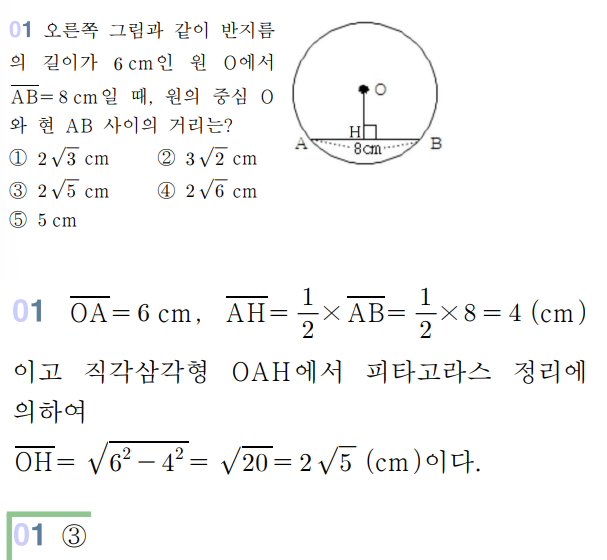


[입력 답안: 틀린답] >> 오답입니다. 선수 단원 [[9수03-17]] 기초 문항(난이도 '하' 우선)으로 이동합니다. (깊이 1)

[튜터 피드백]
 [진단 요약] 입력 답안('틀린답')이 정답('③ $2 \sqrt{5} \mathrm{~cm}$')과 다릅니다.
[작성 풀이 확인] '접선과 반지름이 수직이라는 것만 쓰고 중심각과 원주각 관계를 헷갈렸습니다.' 과정을 기준으로 핵심 수식/성질 적용 여부를 점검해 보세요.
[선수 학습 안내] 본 단원 해결을 위해 선수 성취기준 [9수03-17]의 기초 문항으로 먼저 이동합니다.
[단원: [9수03-17] | 역추적 깊이: 1 | 문항ID: S3_중등_3_003203]
난이도: 하 | 유형: 객관식 | 이미지: /content/unzipped_data/30.수학_교과_문제_풀이과정_데이터/3.개방데이터/1.데이터/Training/01.원천데이터/TS_07.중학교_3학년_01.객관식/S3_중등_3_003203.png

[문제 텍스트]
오른쪽 그림은 축구 경기의 한 장면이다. 이때 두 선수 $\mathrm{A}, \mathrm{B}$ 사이의 거 리는?

(테스트 참고용 정답: ① $3 \sqrt{2} \mathrm{~m}$)


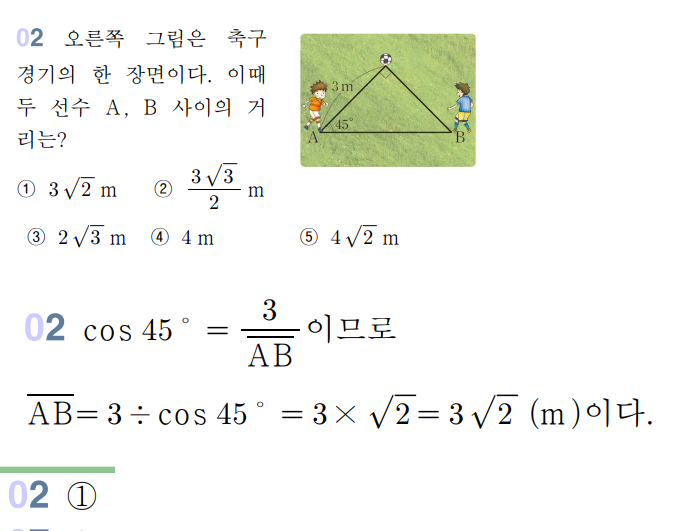


[입력 답안: 틀린답2] >> 오답입니다. 선수 단원 [[8수03-08]] 기초 문항(난이도 '하' 우선)으로 이동합니다. (깊이 2)

[튜터 피드백]
 [진단 요약] 입력 답안('틀린답2')이 정답('① $3 \sqrt{2} \mathrm{~m}$')과 다릅니다.
[작성 풀이 확인] '현에 내린 수선이 현을 이등분하는 부분을 놓쳤습니다.' 과정을 기준으로 핵심 수식/성질 적용 여부를 점검해 보세요.
[선수 학습 안내] 본 단원 해결을 위해 선수 성취기준 [8수03-08]의 기초 문항으로 먼저 이동합니다.
출제할 문항이 없습니다.


In [14]:
import json
import re
from collections import defaultdict
from pathlib import Path
from PIL import Image
from IPython.display import display

INDEX_PATH = Path("/content/processed_math_data/math_problems_index.jsonl")

# ---------------------------------------------------------
# 1. 성취기준별 문항 풀 로드
# ---------------------------------------------------------
problems_by_ach = defaultdict(list)
with open(INDEX_PATH, "r", encoding="utf-8") as f:
    for line in f:
        row = json.loads(line)
        for ach in row.get("ach_2022") or []:
            code = ach.split("]")[0] + "]" if "]" in ach else ach.strip()
            if code:
                problems_by_ach[code].append(row)

PREREQ_MAP = {
    "[9수03-18]": ["[9수03-17]", "[8수03-08]"],
    "[9수03-17]": ["[8수03-08]"],
    "[8수03-08]": [],
}

DIFF_ORDER = {"하": 0, "중": 1, "상": 2}
CIRCLE_NUMS = {"①": "1", "②": "2", "③": "3", "④": "4", "⑤": "5"}

def normalize_answer(text: str) -> str:
    if not text:
        return ""
    s = text.strip()
    for k, v in CIRCLE_NUMS.items():
        s = s.replace(k, v)
    s = re.sub(r"\$+|\\mathrm\{([^}]*)\}|\\text\{([^}]*)\}|\\circ|\^?\{\\?circ\}|\s+", "", s)
    return s.lower()

def check_answer(user_ans: str, gold_ans: str) -> bool:
    u = normalize_answer(user_ans)
    g = normalize_answer(gold_ans)
    if not u or not g:
        return False
    if u == g:
        return True
    for k, v in CIRCLE_NUMS.items():
        if user_ans.strip() in (k, v) and v in g:
            return True
    return u in g and len(u) >= 1

# ---------------------------------------------------------
# 2. VLM 피드백 어댑터 (Qwen2.5-VL 연동 준비 + 폴백 지원)
# ---------------------------------------------------------
class VLMFeedbackEngine:
    def __init__(self, enabled: bool = False, model_id: str = "Qwen/Qwen2.5-VL-7B-Instruct"):
        self.enabled = enabled
        self.model_id = model_id
        self.model = None
        self.processor = None

    def load_model(self):
        if not self.enabled or self.model is not None:
            return
        import torch
        from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration

        self.processor = AutoProcessor.from_pretrained(self.model_id)
        self.model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
            self.model_id,
            torch_dtype=torch.bfloat16 if torch.cuda.is_available() else torch.float32,
            device_map="auto" if torch.cuda.is_available() else None,
        )

    def generate_feedback(
        self,
        problem: dict,
        user_answer: str,
        student_work: str = "",
        student_work_image: str = "",
        next_prereq_ach: str = "",
    ) -> str:
        """학생 답안·풀이 과정을 바탕으로 진단 피드백을 생성합니다."""
        if not self.enabled:
            # 모델 미로드 시에도 동작하는 진단형 폴백 피드백
            lines = [
                f"[진단 요약] 입력 답안('{user_answer}')이 정답('{problem.get('answer')}')과 다릅니다."
            ]
            if student_work:
                lines.append(f"[작성 풀이 확인] '{student_work}' 과정을 기준으로 핵심 수식/성질 적용 여부를 점검해 보세요.")
            if next_prereq_ach:
                lines.append(f"[선수 학습 안내] 본 단원 해결을 위해 선수 성취기준 {next_prereq_ach}의 기초 문항으로 먼저 이동합니다.")
            return "\n".join(lines)

        self.load_model()
        from qwen_vl_utils import process_vision_info

        prompt_text = (
            "당신은 친절한 중·고등 수학 튜터입니다. 아래 문제와 학생의 답안 및 풀이 과정을 보고 "
            "1) 어느 단계에서 오류가 발생했는지, 2) 어떤 기초 개념을 먼저 점검해야 하는지 짧고 명확하게 피드백하세요.\n"
            f"- 성취기준: {problem.get('ach_2022')}\n"
            f"- 문제 텍스트: {problem.get('question_text')}\n"
            f"- 정답: {problem.get('answer')}\n"
            f"- 모범 풀이: {problem.get('solution')}\n"
            f"- 학생 답안: {user_answer}\n"
            f"- 학생 풀이 과정: {student_work or '(미입력)'}\n"
            f"- 다음 역추적 선수 단원: {next_prereq_ach or '(없음)'}"
        )

        content = []
        if problem.get("image_path") and Path(problem["image_path"]).exists():
            content.append({"type": "image", "image": problem["image_path"]})
        if student_work_image and Path(student_work_image).exists():
            content.append({"type": "image", "image": student_work_image})
        content.append({"type": "text", "text": prompt_text})

        messages = [{"role": "user", "content": content}]
        text_input = self.processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        image_inputs, video_inputs = process_vision_info(messages)
        inputs = self.processor(
            text=[text_input],
            images=image_inputs,
            videos=video_inputs,
            padding=True,
            return_tensors="pt",
        ).to(self.model.device)

        generated_ids = self.model.generate(**inputs, max_new_tokens=300)
        trimmed_ids = [
            out_ids[len(in_ids):] for in_ids, out_ids in zip(inputs.input_ids, generated_ids)
        ]
        output_text = self.processor.batch_decode(trimmed_ids, skip_special_tokens=True)[0]
        return output_text.strip()

# ---------------------------------------------------------
# 3. 난이도 '하' 우선 + 이미지 출력 + VLM 피드백 루프
# ---------------------------------------------------------
class MathRemediationLoopV2:
    def __init__(self, target_ach: str, vlm_engine: VLMFeedbackEngine, max_depth: int = 2, prefer_easy: bool = True):
        self.target_ach = target_ach
        self.current_ach = target_ach
        self.max_depth = max_depth
        self.prefer_easy = prefer_easy
        self.vlm = vlm_engine

        self.trace_stack = []
        self.visited_ach = {target_ach}
        self.used_problem_ids = set()
        self.current_problem = None
        self.logs = []

    def pick_problem(self, ach: str, prioritize_easy: bool = False):
        pool = problems_by_ach.get(ach, [])
        unused = [p for p in pool if p["id"] not in self.used_problem_ids]
        candidates = unused if unused else pool
        if not candidates:
            return None

        if prioritize_easy or self.prefer_easy:
            # 난이도 '하'(0) -> '중'(1) -> '상'(2) 순으로 정렬
            candidates = sorted(candidates, key=lambda x: DIFF_ORDER.get(x.get("difficulty", "중"), 1))

        chosen = candidates[0]
        self.used_problem_ids.add(chosen["id"])
        return chosen

    def start_or_get_problem(self, force_new: bool = False, prioritize_easy: bool = False):
        if self.current_problem is None or force_new:
            self.current_problem = self.pick_problem(self.current_ach, prioritize_easy=prioritize_easy)
        return self.current_problem

    def step(self, user_answer: str, student_work: str = "", student_work_image: str = ""):
        prob = self.start_or_get_problem(force_new=False)
        if not prob:
            return {"status": "NO_PROBLEM", "message": f"{self.current_ach} 문항 풀이 비어 있습니다."}

        is_correct = check_answer(user_answer, prob.get("answer", ""))
        depth = len(self.trace_stack)

        if is_correct:
            self.logs.append({
                "ach": self.current_ach,
                "problem_id": prob["id"],
                "difficulty": prob.get("difficulty"),
                "depth": depth,
                "user_answer": user_answer,
                "student_work": student_work,
                "is_correct": True,
            })
            if self.trace_stack:
                self.current_ach = self.trace_stack.pop()
                # 상위 단원 복귀 시에도 난이도 '하' 우선으로 재도전 문항 출제
                next_prob = self.start_or_get_problem(force_new=True, prioritize_easy=True)
                return {
                    "status": "RECOVERED_RETRY",
                    "message": f"정답입니다! 상위 단계 [{self.current_ach}]로 복귀해 난이도 우선 새 문항을 출제합니다.",
                    "feedback": None,
                    "next_problem": next_prob,
                }
            else:
                next_prob = self.start_or_get_problem(force_new=True, prioritize_easy=False)
                return {
                    "status": "CORRECT_NEXT",
                    "message": f"정답입니다! [{self.current_ach}] 단원의 다음 문항을 출제합니다.",
                    "feedback": None,
                    "next_problem": next_prob,
                }

        # 오답 처리
        next_prereq = ""
        if depth < self.max_depth:
            prereqs = PREREQ_MAP.get(self.current_ach, [])
            next_prereq = next((p for p in prereqs if p not in self.visited_ach), "")

        feedback_msg = self.vlm.generate_feedback(
            problem=prob,
            user_answer=user_answer,
            student_work=student_work,
            student_work_image=student_work_image,
            next_prereq_ach=next_prereq,
        )

        self.logs.append({
            "ach": self.current_ach,
            "problem_id": prob["id"],
            "difficulty": prob.get("difficulty"),
            "depth": depth,
            "user_answer": user_answer,
            "student_work": student_work,
            "is_correct": False,
            "feedback": feedback_msg,
        })

        if next_prereq:
            self.trace_stack.append(self.current_ach)
            self.visited_ach.add(next_prereq)
            self.current_ach = next_prereq
            # 역추적 진입 시 난이도 '하' 기초 문항 우선 출제
            next_prob = self.start_or_get_problem(force_new=True, prioritize_easy=True)
            return {
                "status": "TRACE_DOWN",
                "message": f"오답입니다. 선수 단원 [{self.current_ach}] 기초 문항(난이도 '하' 우선)으로 이동합니다. (깊이 {len(self.trace_stack)})",
                "feedback": feedback_msg,
                "hint_solution": prob.get("solution", ""),
                "next_problem": next_prob,
            }

        next_prob = self.start_or_get_problem(force_new=True, prioritize_easy=True)
        return {
            "status": "MAX_DEPTH_EXPLAIN",
            "message": f"오답입니다. 역추적 한계 도달로 [{self.current_ach}] 풀이를 제시하고 새 문항으로 이어갑니다.",
            "feedback": feedback_msg,
            "hint_solution": prob.get("solution", ""),
            "next_problem": next_prob,
        }

def show_problem_with_image(loop_obj, prob):
    if not prob:
        print("출제할 문항이 없습니다.")
        return
    print("=" * 65)
    print(f"[단원: {loop_obj.current_ach} | 역추적 깊이: {len(loop_obj.trace_stack)} | 문항ID: {prob['id']}]")
    print(f"난이도: {prob.get('difficulty')} | 유형: {prob.get('problem_type')} | 이미지: {prob.get('image_path')}")
    print("\n[문제 텍스트]")
    print(prob.get("question_text"))
    print(f"\n(테스트 참고용 정답: {prob.get('answer')})")

    img_path = prob.get("image_path")
    if img_path and Path(img_path).exists():
        display(Image.open(img_path))
    print("=" * 65)

# ---------------------------------------------------------
# 4. 테스트 실행 (INTERACTIVE=True 로 바꾸면 직접 입력 가능)
# ---------------------------------------------------------
INTERACTIVE = False
ENABLE_VLM = False  # 실제 Qwen2.5-VL 추론을 돌리려면 True로 변경

vlm_engine = VLMFeedbackEngine(enabled=ENABLE_VLM)
loop = MathRemediationLoopV2(target_ach="[9수03-18]", vlm_engine=vlm_engine, max_depth=2, prefer_easy=True)

first_prob = loop.start_or_get_problem(force_new=True, prioritize_easy=False)
show_problem_with_image(loop, first_prob)

if INTERACTIVE:
    while True:
        ans = input("\n학생 답안 입력 (종료: q): ").strip()
        if ans.lower() == "q":
            break
        work = input("학생 풀이 과정 입력 (없으면 Enter): ").strip()
        res = loop.step(user_answer=ans, student_work=work)
        print("\n>>", res["message"])
        if res.get("feedback"):
            print("\n[튜터 피드백]\n", res["feedback"])
        show_problem_with_image(loop, res.get("next_problem"))
else:
    # 자동 시나리오: 풀이 과정을 함께 입력하며 2단계 역추적 후 순차 복귀 확인
    simulated_steps = [
        ("틀린답", "접선과 반지름이 수직이라는 것만 쓰고 중심각과 원주각 관계를 헷갈렸습니다."),
        ("틀린답2", "현에 내린 수선이 현을 이등분하는 부분을 놓쳤습니다."),
        (None, ""),  # 현재 출제된 기초 문항의 정답 자동 입력
        (None, ""),  # 상위 단원 복귀 문항의 정답 자동 입력
        (None, ""),  # 본 단원 복귀 문항의 정답 자동 입력
    ]
    for ans, work in simulated_steps:
        if not loop.current_problem:
            break
        actual_ans = ans if ans is not None else loop.current_problem["answer"]
        res = loop.step(user_answer=actual_ans, student_work=work)
        print(f"\n[입력 답안: {actual_ans}] >> {res['message']}")
        if res.get("feedback"):
            print("\n[튜터 피드백]\n", res["feedback"])
        show_problem_with_image(loop, res.get("next_problem"))

2. 실전 연결 시 체크할 팁
실제 VLM 모델 활성화(ENABLE_VLM = True): Colab GPU(T4/A100 등)에서 Qwen/Qwen2.5-VL-7B-Instruct를 바로 띄울 때는 메모리 절약을 위해 4bit 양자화(BitsAndBytesConfig)나 max_new_tokens 제한을 함께 두는 것이 안전합니다.

학생 손글씨 풀이 이미지 입력: 학생이 찍은 풀이 사진(student_work_image) 경로를 step()에 넘기면, VLMFeedbackEngine이 원본 문제 이미지 + 학생 손글씨 풀이 이미지 두 장을 함께 보고 어디서 막혔는지 진단할 수 있도록 구성해 두었습니다.

이 테스트 루프를 돌려보신 뒤, 실제 이미지와 difficulty 값 출력 모습이나 특정 학년/단원(PREREQ_MAP) 확장이 필요하시면 언제든 알려주세요!